<a href="https://colab.research.google.com/github/sikdarananya/Assignments/blob/master/ML_Assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    roc_curve,
)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
os.makedirs("model", exist_ok=True)
sns.set_theme(style="whitegrid")
print("Setup complete. 'model/' directory ready.")

Setup complete. 'model/' directory ready.


In [4]:
!wget -q https://archive.ics.uci.edu/static/public/222/bank+marketing.zip -O bank_marketing.zip
!unzip -q -o bank_marketing.zip
!unzip -q -o bank-additional.zip
!find . -maxdepth 3 -name "*bank-additional*.csv"

./bank-additional/bank-additional-full.csv
./bank-additional/bank-additional.csv


In [5]:
# Replace with your dataset path (example uses UCI Bank Marketing 'bank-additional-full.csv')
DATA_PATH = "bank-additional/bank-additional-full.csv"
TARGET_COL = "y"

df = pd.read_csv(DATA_PATH, sep=";")

# Standardize missing-value markers if your dataset uses strings like 'unknown' or '?'
df.replace(["unknown", "?"], np.nan, inplace=True)

# Map binary target to 0/1 (adjust mapping if using a different binary or multi-class target)
if df[TARGET_COL].dtype == object:
    df[TARGET_COL] = df[TARGET_COL].map({"no": 0, "yes": 1})

print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")
print("\nFeature Data Types:\n", df.dtypes.value_counts())

missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Pct": (df.isnull().mean() * 100).round(2)
})
print("\nMissing Values per Column:\n", missing_summary[missing_summary["Missing_Count"] > 0])

print("\nTarget Class Distribution (Counts):\n", df[TARGET_COL].value_counts())
print("\nTarget Class Distribution (Proportions):\n", df[TARGET_COL].value_counts(normalize=True).round(4))

Shape: 41188 rows x 21 columns

Feature Data Types:
 object     10
int64       6
float64     5
Name: count, dtype: int64

Missing Values per Column:
            Missing_Count  Missing_Pct
job                  330         0.80
marital               80         0.19
education           1731         4.20
default             8597        20.87
housing              990         2.40
loan                 990         2.40

Target Class Distribution (Counts):
 y
0    36548
1     4640
Name: count, dtype: int64

Target Class Distribution (Proportions):
 y
0    0.8873
1    0.1127
Name: proportion, dtype: float64


In [6]:
before_dedup = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicates removed: {before_dedup - len(df)} (Remaining rows: {len(df)})")

X = df.drop(columns=[TARGET_COL])
y = df[TARGET_COL]

# Stratified 80:20 split preserves class imbalance across train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_SEED
)

# Export test_data.csv for the GitHub repository requirement
test_export = X_test.copy()
test_export[TARGET_COL] = y_test
test_export.to_csv("test_data.csv", index=False)

print(f"X_train shape: {X_train.shape} | X_test shape: {X_test.shape}")
print("Train target ratio:\n", y_train.value_counts(normalize=True).round(4))
print("Test target ratio:\n", y_test.value_counts(normalize=True).round(4))
print("Saved 'test_data.csv' successfully.")

Duplicates removed: 12 (Remaining rows: 41176)
X_train shape: (32940, 20) | X_test shape: (8236, 20)
Train target ratio:
 y
0    0.8873
1    0.1127
Name: proportion, dtype: float64
Test target ratio:
 y
0    0.8873
1    0.1127
Name: proportion, dtype: float64
Saved 'test_data.csv' successfully.


In [7]:
num_cols = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print(f"Numerical features ({len(num_cols)}): {num_cols}")
print(f"Categorical features ({len(cat_cols)}): {cat_cols}")

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

# Fitted strictly inside each model's Pipeline on X_train to prevent any data leakage
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, num_cols),
        ("cat", categorical_pipeline, cat_cols)
    ],
    remainder="drop"
)

Numerical features (10): ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categorical features (10): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


In [8]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_SEED
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=10,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=RANDOM_SEED
    ),
    "kNN": KNeighborsClassifier(
        n_neighbors=7,
        weights="distance",
        n_jobs=-1
    ),
    "Naive Bayes": GaussianNB(),
    "Random Forest (Ensemble)": RandomForestClassifier(
        n_estimators=200,
        max_depth=14,
        class_weight="balanced",
        random_state=RANDOM_SEED,
        n_jobs=-1
    )
}

metrics_rows = []
roc_curves = {}

for model_name, estimator in models.items():
    full_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", estimator)
    ])

    # Fit ONLY on training data
    full_pipeline.fit(X_train, y_train)

    # Save trained pipeline into model/
    file_slug = (
        model_name.lower()
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
    )
    model_path = os.path.join("model", f"{file_slug}.pkl")
    joblib.dump(full_pipeline, model_path)

    # Evaluate on held-out test set
    y_pred = full_pipeline.predict(X_test)
    y_proba = full_pipeline.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    mcc = matthews_corrcoef(y_test, y_pred)

    metrics_rows.append({
        "ML Model Name": model_name,
        "Accuracy": round(acc, 4),
        "AUC": round(auc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1": round(f1, 4),
        "MCC": round(mcc, 4)
    })

    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_curves[model_name] = (fpr, tpr, auc)
    print(f"Trained & saved {model_path} | AUC={auc:.4f} | F1={f1:.4f} | MCC={mcc:.4f}")

results_df = pd.DataFrame(metrics_rows)
print("\n=== Final Comparison Table ===")
display(results_df)

Trained & saved model/logistic_regression.pkl | AUC=0.9401 | F1=0.5973 | MCC=0.5733
Trained & saved model/decision_tree.pkl | AUC=0.9228 | F1=0.5903 | MCC=0.5661
Trained & saved model/knn.pkl | AUC=0.8932 | F1=0.4882 | MCC=0.4450
Trained & saved model/naive_bayes.pkl | AUC=0.8474 | F1=0.4156 | MCC=0.3728
Trained & saved model/random_forest_ensemble.pkl | AUC=0.9452 | F1=0.6377 | MCC=0.6002

=== Final Comparison Table ===


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.8628,0.9401,0.4462,0.9030,0.5973,0.5733
1,Decision Tree,0.8589,0.9228,0.4387,0.9019,0.5903,0.5661
2,kNN,0.9023,0.8932,0.5953,0.4138,0.4882,0.4450
3,Naive Bayes,0.7347,0.8474,0.2764,0.8373,0.4156,0.3728
4,Random Forest (Ensemble),0.8949,0.9452,0.5212,0.8211,0.6377,0.6002


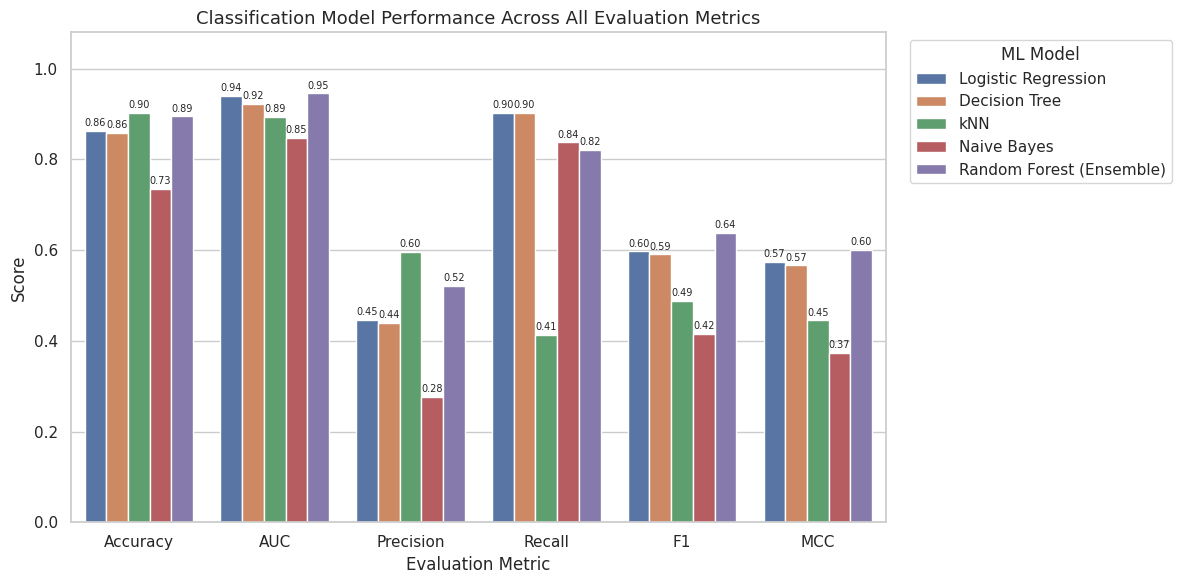

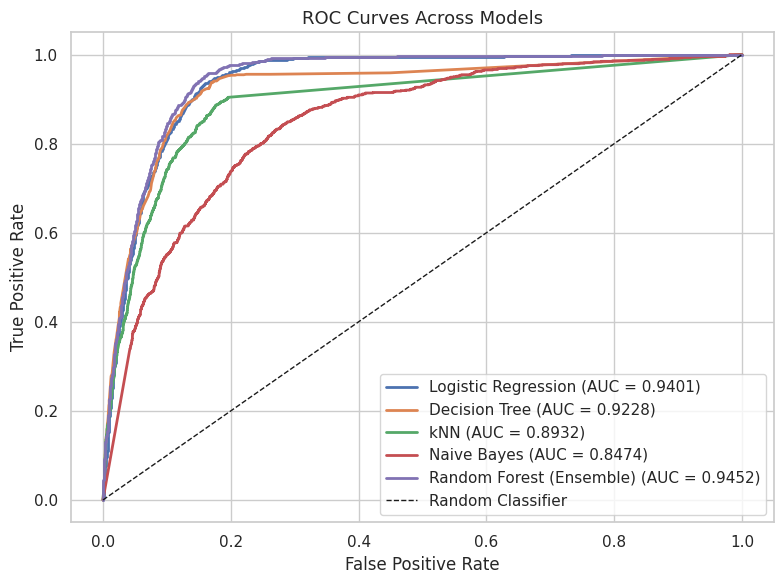

In [9]:
# 1. Grouped Bar Chart across all 6 evaluation metrics
melted = results_df.melt(
    id_vars="ML Model Name",
    value_vars=["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))
ax = sns.barplot(data=melted, x="Metric", y="Score", hue="ML Model Name")
plt.title("Classification Model Performance Across All Evaluation Metrics", fontsize=13)
plt.xlabel("Evaluation Metric")
plt.ylabel("Score")
plt.ylim(0, 1.08)
plt.legend(title="ML Model", bbox_to_anchor=(1.02, 1), loc="upper left")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=7, padding=2)

plt.tight_layout()
plt.savefig("metrics_bar_chart.png", dpi=300)
plt.show()

# 2. ROC Curve Comparison
plt.figure(figsize=(8, 6))
for model_name, (fpr, tpr, auc_val) in roc_curves.items():
    plt.plot(fpr, tpr, linewidth=2, label=f"{model_name} (AUC = {auc_val:.4f})")

plt.plot([0, 1], [0, 1], "k--", linewidth=1, label="Random Classifier")
plt.title("ROC Curves Across Models", fontsize=13)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("roc_comparison.png", dpi=300)
plt.show()